In [1]:
# ===== 0. Local-or-IBM setup =====
import warnings
warnings.filterwarnings("ignore")
import numpy as np
import matplotlib.pyplot as plt

use_ibm = False
try:
    from qiskit_ibm_runtime import QiskitRuntimeService, Sampler as IBMSampler
    try:
        service = QiskitRuntimeService()
        backend = service.backend("ibmq_qasm_simulator")
        sampler = IBMSampler(session=service)
        use_ibm = True
        print("Using IBM runtime:", backend.name())
    except Exception:
        use_ibm = False
except Exception:
    use_ibm = False

if not use_ibm:
    try:
        from qiskit_aer import AerSimulator
        from qiskit_aer.primitives import Sampler as AerSampler
        simulator = AerSimulator()
        sampler = AerSampler()
        backend = simulator
        print("Using local AerSimulator / AerSampler")
    except Exception:
        from qiskit import Aer
        backend = Aer.get_backend("aer_simulator")
        sampler = None
        print("Using qiskit.Aer.get_backend('aer_simulator') (sampler not available)")

# Standard Qiskit imports
from qiskit import QuantumCircuit, transpile, Aer, IBMQ
from qiskit.visualization import *
from qiskit.utils import algorithm_globals
from qiskit.algorithms.minimum_eigensolvers import SamplingVQE
from qiskit.algorithms.optimizers import SPSA
from qiskit.circuit.library import RealAmplitudes
from qiskit_optimization import QuadraticProgram
from qiskit_optimization.algorithms import MinimumEigenOptimizer

# Classical solver import
import cplex
from cplex.exceptions import CplexError
import math


Using local AerSimulator / AerSampler


In [2]:
# ===== 1. Problem Initialization =====
n = 3  # number of nodes
K = 2  # number of vehicles

class Initializer:
    def __init__(self, n):
        self.n = n

    def generate_instance(self):
        np.random.seed(1543)
        xc = (np.random.rand(self.n) - 0.5) * 10
        yc = (np.random.rand(self.n) - 0.5) * 10
        instance = np.zeros([self.n, self.n])
        for ii in range(self.n):
            for jj in range(ii + 1, self.n):
                instance[ii, jj] = (xc[ii] - xc[jj]) ** 2 + (yc[ii] - yc[jj]) ** 2
                instance[jj, ii] = instance[ii, jj]
        return xc, yc, instance

initializer = Initializer(n)
xc, yc, instance = initializer.generate_instance()


In [3]:
# ===== 2. Classical Optimizer =====
class ClassicalOptimizer:
    def __init__(self, instance, n, K):
        self.instance = instance
        self.n = n
        self.K = K

    def compute_allowed_combinations(self):
        f = math.factorial
        return f(self.n) / f(self.K) / f(self.n - self.K)

    def cplex_solution(self):
        instance, n, K = self.instance, self.n, self.K
        my_obj = list(instance.reshape(1, n**2)[0]) + [0.0 for _ in range(n-1)]
        my_ub = [1]*(n**2 + n-1)
        my_lb = [0]* (n**2) + [0.1]*(n-1)
        my_ctype = "I"* (n**2) + "C"*(n-1)
        my_rhs = 2*([K] + [1]*(n-1)) + [1-0.1]*((n-1)**2 - (n-1)) + [0]*n
        my_sense = "E"* (2*n) + "L"* ((n-1)**2 - (n-1)) + "E"*n

        try:
            my_prob = cplex.Cplex()
            self.populatebyrow(my_prob, my_obj, my_ub, my_lb, my_ctype, my_sense, my_rhs)
            my_prob.solve()
        except CplexError as exc:
            print(exc)
            return

        x = np.array(my_prob.solution.get_values())
        cost = my_prob.solution.get_objective_value()
        return x, cost

    def populatebyrow(self, prob, my_obj, my_ub, my_lb, my_ctype, my_sense, my_rhs):
        n = self.n
        prob.objective.set_sense(prob.objective.sense.minimize)
        prob.variables.add(obj=my_obj, lb=my_lb, ub=my_ub, types=my_ctype)
        prob.set_log_stream(None)
        prob.set_error_stream(None)
        prob.set_warning_stream(None)
        prob.set_results_stream(None)
        rows = []
        for ii in range(n):
            col = [x for x in range(ii*n, ii*n+n)]
            coef = [1]*n
            rows.append([col, coef])
        for ii in range(n):
            col = [x for x in range(ii, n**2, n)]
            coef = [1]*n
            rows.append([col, coef])
        for ii in range(n):
            for jj in range(n):
                if ii != jj and ii*jj > 0:
                    col = [ii + jj*n, n**2+ii-1, n**2+jj-1]
                    coef = [1,1,-1]
                    rows.append([col,coef])
        for ii in range(n):
            col = [ii*(n+1)]
            coef = [1]
            rows.append([col,coef])
        prob.linear_constraints.add(lin_expr=rows, senses=my_sense, rhs=my_rhs)

classical_optimizer = ClassicalOptimizer(instance, n, K)
print("Number of feasible solutions =", classical_optimizer.compute_allowed_combinations())

x, classical_cost = classical_optimizer.cplex_solution()
z = [x[ii] for ii in range(n**2) if ii//n != ii%n]
print("Classical solution vector:", z)


Number of feasible solutions = 3.0
Classical solution vector: [1.0, 1.0, 1.0, 0.0, 1.0, 0.0]


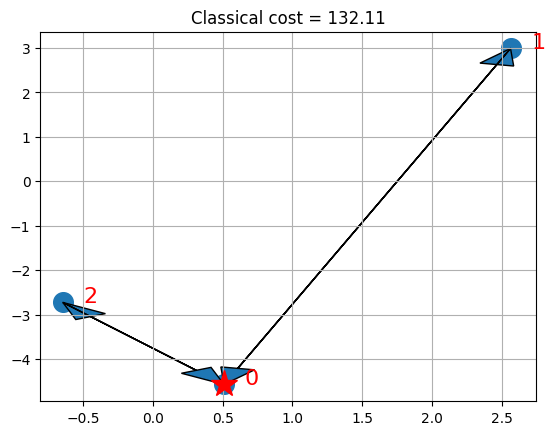

In [4]:
# ===== 3. Visualization =====
def visualize_solution(xc, yc, x, C, n, K, title_str):
    plt.figure()
    plt.scatter(xc, yc, s=200)
    for i in range(len(xc)):
        plt.annotate(i, (xc[i]+0.15, yc[i]), size=16, color='r')
    plt.plot(xc[0], yc[0], 'r*', ms=20)
    plt.grid()
    for ii in range(n**2):
        if x[ii] > 0:
            ix = ii // n
            iy = ii % n
            plt.arrow(xc[ix], yc[ix], xc[iy]-xc[ix], yc[iy]-yc[ix],
                      length_includes_head=True, head_width=0.25)
    plt.title(title_str + " cost = " + str(int(C*100)/100.0))
    plt.show()

visualize_solution(xc, yc, x, classical_cost, n, K, "Classical")


In [5]:
# ===== 4. Quantum Optimizer =====
class QuantumOptimizer:
    def __init__(self, instance, n, K):
        self.instance = instance
        self.n = n
        self.K = K

    def binary_representation(self, x_sol=0):
        instance, n, K = self.instance, self.n, self.K
        A = np.max(instance)*100
        instance_vec = instance.reshape(n**2)
        w_list = [instance_vec[x] for x in range(n**2) if instance_vec[x] > 0]
        w = np.zeros(n*(n-1))
        for ii in range(len(w_list)): w[ii] = w_list[ii]

        Id_n = np.eye(n)
        Im_n_1 = np.ones([n-1,n-1])
        Iv_n_1 = np.ones(n); Iv_n_1[0]=0
        Iv_n = np.ones(n-1)
        neg_Iv_n_1 = np.ones(n)-Iv_n_1

        v = np.zeros([n, n*(n-1)])
        for ii in range(n):
            count = ii-1
            for jj in range(n*(n-1)):
                if jj//(n-1)==ii: count=ii
                if jj//(n-1)!=ii and jj%(n-1)==count: v[ii][jj]=1.0
        vn = np.sum(v[1:], axis=0)

        Q = A*(np.kron(Id_n, Im_n_1)+np.dot(v.T,v))
        g = w - 2*A*(np.kron(Iv_n_1,Iv_n)+vn.T) - 2*A*K*(np.kron(neg_Iv_n_1,Iv_n)+v[0].T)
        c = 2*A*(n-1)+2*A*(K**2)

        try:
            max(x_sol)
            fun = lambda x: np.dot(np.around(x), np.dot(Q, np.around(x)))+np.dot(g, np.around(x))+c
            cost = fun(x_sol)
        except:
            cost=0

        return Q,g,c,cost

    def construct_problem(self,Q,g,c) -> QuadraticProgram:
        qp = QuadraticProgram()
        for i in range(n*(n-1)): qp.binary_var(str(i))
        qp.objective.quadratic = Q
        qp.objective.linear = g
        qp.objective.constant = c
        return qp

    def solve_problem(self, qp):
        algorithm_globals.random_seed=10598
        vqe = SamplingVQE(sampler=sampler, optimizer=SPSA(), ansatz=RealAmplitudes())
        optimizer = MinimumEigenOptimizer(min_eigen_solver=vqe)
        result = optimizer.solve(qp)
        _,_,_,level = self.binary_representation(x_sol=result.x)
        return result.x, level

quantum_optimizer = QuantumOptimizer(instance, n, K)
Q, g, c, binary_cost = quantum_optimizer.binary_representation(x_sol=z)
qp = quantum_optimizer.construct_problem(Q,g,c)
quantum_solution, quantum_cost = quantum_optimizer.solve_problem(qp)


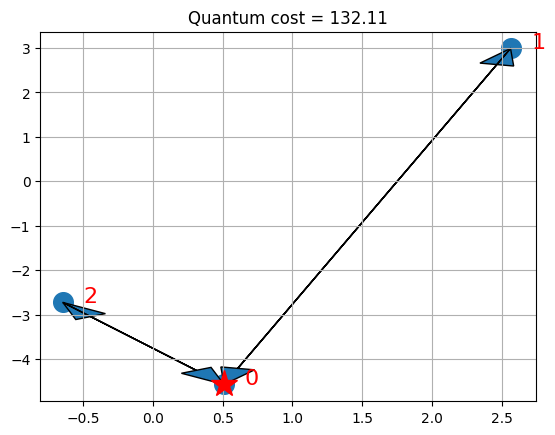

In [6]:
# ===== 5. Quantum Solution Vector Compatible with Classical =====
x_quantum = np.zeros(n**2)
kk = 0
for ii in range(n**2):
    if ii//n != ii%n:
        x_quantum[ii] = quantum_solution[kk]
        kk += 1

visualize_solution(xc, yc, x_quantum, quantum_cost, n, K, "Quantum")


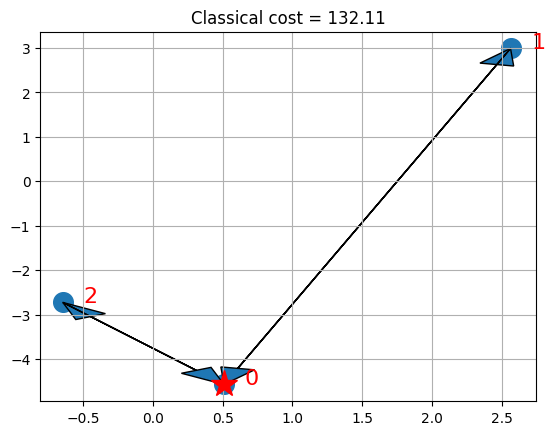

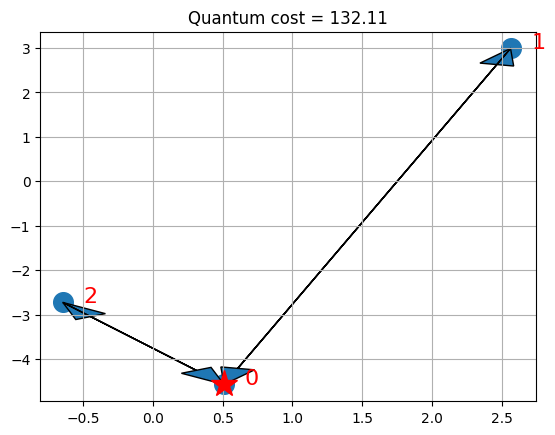

Classical cost: 132.1114811568365
Quantum cost: 132.11148115684045


In [7]:
# ===== 6. Compare Classical and Quantum =====
if x is not None:
    visualize_solution(xc, yc, x, classical_cost, n, K, "Classical")
    visualize_solution(xc, yc, x_quantum, quantum_cost, n, K, "Quantum")
print("Classical cost:", classical_cost)
print("Quantum cost:", quantum_cost)
